In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [2]:
df = pd.read_csv(
    "data/nifty_cleaned.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return_%,MA_50,MA_200,Year
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400,NaN,NaN,NaN,2016
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700,0.476776,NaN,NaN,2016
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000,0.022504,NaN,NaN,2016
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600,-0.240244,NaN,NaN,2016
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900,0.797464,NaN,NaN,2016


In [3]:
df["Weekday"] = df["Date"].dt.day_name()

df["Abs_Return"] = (
    df["Daily_Return_%"]
    .abs()
)

In [ ]:
# 1.Hypothesis 1:
# Mean Daily Return ≠ 0
# 2.Null Hypothesis
# H0:
# Mean return = 0
# 3.Alternative Hypothesis
# H1:
# Mean return ≠ 0

In [4]:
# One-Sample T-Test
returns = (
    df["Daily_Return_%"]
    .dropna()
)

t_stat, p_value = stats.ttest_1samp(
    returns,
    popmean=0
)

print("T Statistic:", t_stat)
print("P-value:", p_value)


T Statistic: 2.3630009439217305
P-value: 0.018204358383803833


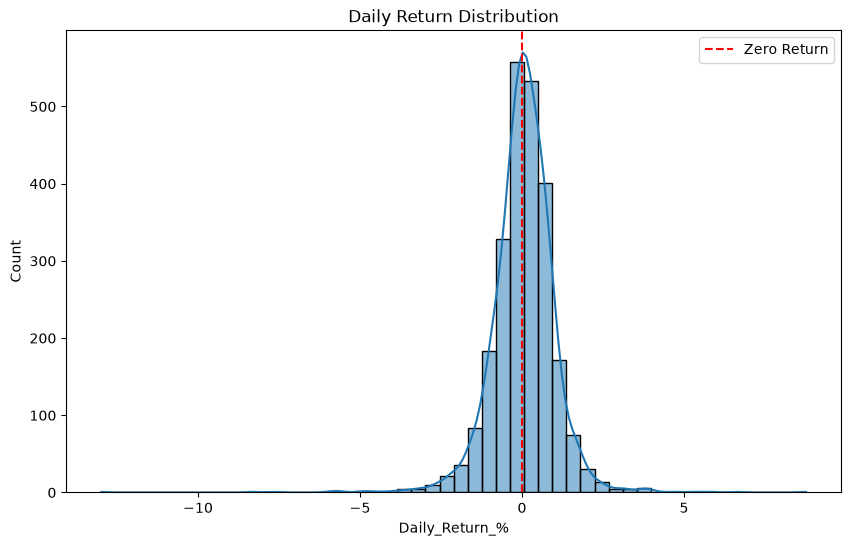

In [5]:
# Return Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    returns,
    bins=50,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Return"
)

plt.title(
    "Daily Return Distribution"
)

plt.legend()

plt.show()

In [7]:
# Interpretation
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Mean return differs significantly from zero.")
else:
    print("Fail to reject H0")
    print("No significant evidence that mean return differs from zero.")

Reject H0
Mean return differs significantly from zero.


In [8]:
# Hypothesis 2
# COVID Volatility vs Normal Years

In [9]:
# Create Volatility Groups
covid_returns = (
    df[
        df["Year"] == 2020
    ]["Daily_Return_%"]
    .dropna()
)

normal_returns = (
    df[
        (df["Year"] >= 2017)
        &
        (df["Year"] <= 2019)
    ]["Daily_Return_%"]
    .dropna()
)

In [10]:
# Levene Test
levene_stat, levene_p = stats.levene(
    covid_returns,
    normal_returns
)

print("Levene Statistic:", levene_stat)
print("P-value:", levene_p)


Levene Statistic: 91.63878320669023
P-value: 8.14562327496182e-21


In [11]:
# Welch T-Test
t_stat2, p_value2 = stats.ttest_ind(
    covid_returns,
    normal_returns,
    equal_var=False
)

print("T Statistic:", t_stat2)
print("P-value:", p_value2)


T Statistic: 0.14417031924750762
P-value: 0.8854716673109008


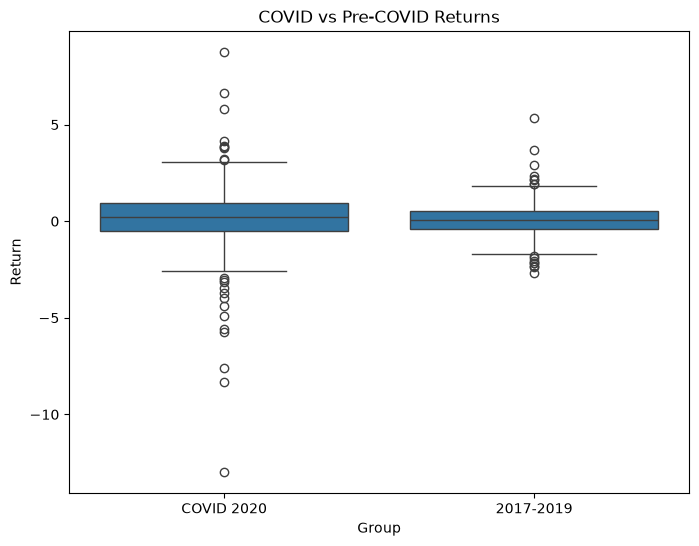

In [13]:
# Boxplot
compare_df = pd.DataFrame(
    {
        "Return":
        pd.concat(
            [
                covid_returns,
                normal_returns
            ]
        ),

        "Group":
        (
            ["COVID 2020"] * len(covid_returns)
            +
            ["2017-2019"] * len(normal_returns)
        )
    }
)

plt.figure(figsize=(8,6))

sns.boxplot(
    x="Group",
    y="Return",
    data=compare_df
)

plt.title(
    "COVID vs Pre-COVID Returns"
)

plt.show()

In [14]:
# 1. Hypothesis 3:
# Day-of-Week Effect
# 2. Null:
# Average returns are equal across weekdays.
# 3. Alternative:
# At least one weekday has a different average return.

In [15]:
# Prepare Groups
weekday_groups = []

for day in [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]:
    weekday_groups.append(
        df[
            df["Weekday"] == day
        ]["Daily_Return_%"].dropna()
    )


In [17]:
# ANOVA Test
f_stat, p_value3 = stats.f_oneway(
    *weekday_groups
)

print("F Statist*c:", f_stat)
print("P-value:", p_value3)

F Statist*c: 2.3843154388910226
P-value: 0.04928120549738427


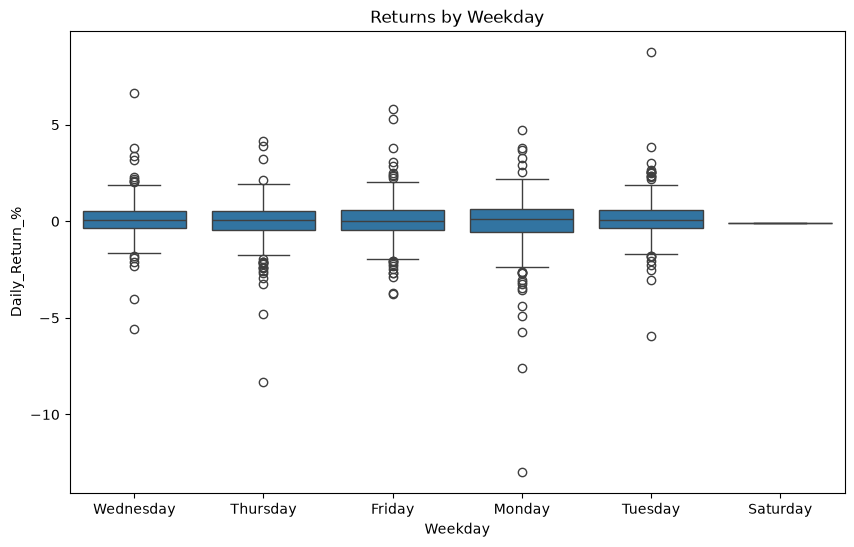

In [21]:
# Weekday Visualization
plt.figure(figsize=(10,6))

sns.boxplot(
    x="Weekday",
    y="Daily_Return_%",
    data=df
)

plt.title(
    "Returns by Weekday"
)

plt.show()

In [22]:
# Hypothesis 4
# Volume vs Absolute Return
# From Week 1:
# Correlation ≈ very weak
# Yahoo index volume may be unreliable

In [23]:
corr, p_value4 = stats.pearsonr(
    df["Volume"],
    df["Abs_Return"]
)

print("Correlation:", corr)
print("P-value:", p_value4)

Correlation: nan
P-value: nan


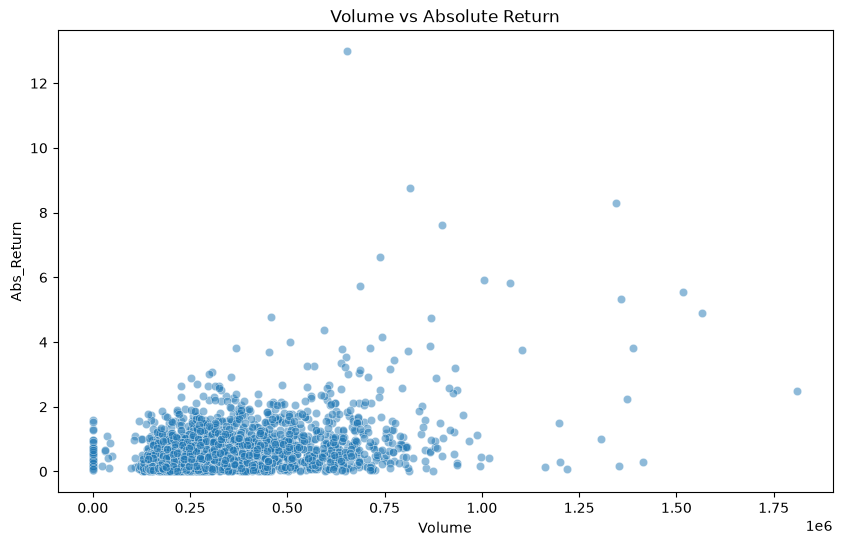

In [24]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Volume",
    y="Abs_Return",
    data=df,
    alpha=0.5
)

plt.title(
    "Volume vs Absolute Return"
)

plt.show()

In [26]:
print("WEEK 3 SUMMARY")

print("- Tested whether mean daily return differs from zero")
print("- Compared COVID and pre-COVID market behavior")
print("- Evaluated return variance using Levene's test")
print("- Applied Welch's t-test for unequal variances")
print("- Investigated weekday effects using ANOVA")
print("- Explored volume and absolute return relationship")
print("- Interpreted statistical significance using p-values")

WEEK 3 SUMMARY
- Tested whether mean daily return differs from zero
- Compared COVID and pre-COVID market behavior
- Evaluated return variance using Levene's test
- Applied Welch's t-test for unequal variances
- Investigated weekday effects using ANOVA
- Explored volume and absolute return relationship
- Interpreted statistical significance using p-values
